# UCE Airfoil Self-Noise

## Imports

In [2]:
import os
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from scipy.stats import linregress
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

## a) Load and inspect data
- Source: [(https://www.geeksforgeeks.org/pandas/pandas-tutorial/)]

We read data from a CSV file using the pandas `read_csv()` function. The `filepath_or_buffer` parameter accepts the path to the CSV. The `sep` parameter is the separator, where the default is `,`. The `header` parameter accepts a list of `int` row numbers to use as column names. If no names are passed and `header=None`, pandas assigns default column labels `0`, `1`, `2`, and so on. The `names` parameter lets us provide our own column names for the data instead of using the header row. The data file we use uses whitespace as the separator, so we use the `\s+` separator to indicate any one or more whitespace characters (space, tab, newline, etc.). The data file we load does not have column headers, only data, so we use `header=None` and assign our own column names.

In [3]:
base_dir = os.getcwd()
data_filepath = os.path.join(base_dir, "airfoil_self_noise.dat")

data = pd.read_csv(
    data_filepath,
    sep=r"\s+",
    header=None,
    names=[
        "Frequency", "Angle of attack", "Chord length",
        "Free-stream velocity", "Suction-side displacement thickness",
        "Sound pressure level"])

display(data.head())

# Check data types and missing values
display(data.dtypes)
display(data.isna().sum())

,Frequency,Angle of attack,Chord length,Free-stream velocity,Suction-side displacement thickness,Sound pressure level
0,800,0.0,0.3048,71.3,0.002663,126.201
1,1000,0.0,0.3048,71.3,0.002663,125.201
2,1250,0.0,0.3048,71.3,0.002663,125.951
3,1600,0.0,0.3048,71.3,0.002663,127.591
4,2000,0.0,0.3048,71.3,0.002663,127.461


Frequency                                int64
Angle of attack                        float64
Chord length                           float64
Free-stream velocity                   float64
Suction-side displacement thickness    float64
Sound pressure level                   float64
dtype: object

Frequency                              0
Angle of attack                        0
Chord length                           0
Free-stream velocity                   0
Suction-side displacement thickness    0
Sound pressure level                   0
dtype: int64

There are no missing data. All of the data are the `float` type, except for `Frequency`, which is the `int` type. This indicates that all variables are continuous except `Frequency`, which is discrete. The `Frequency` values fall into distict bins.

### Frequency vs sound pressure scatterplot
- Source: [(https://www.geeksforgeeks.org/artificial-intelligence/regression-analysis-with-scipy/)]

Regression is used to test the relationship between one or more independent variable and a single dependent variables. In linear regression, the data is modeled as a best-fit line with the equation: $y=mx+b$, where `y` is the dependent variable and `x` is a single independent variable, and all other independent variables are help constant. `m` is the slope, and `b` is the y-intercept. We perform linear regression using SciPy's `linregress()` function. This calculates the slope, intercept, and R squared value of the line-of-best-fit.

Next, we visualize the original data points and the regression line using Matplotlib's `scatter()`. The `alpha` parameter controls the opacity of the data points. `plt.plot(x, y)` plots a straight line, `plt.plot(x, m * x + b)` plots the line of best fit. We include the `R^2` score in the line's label.

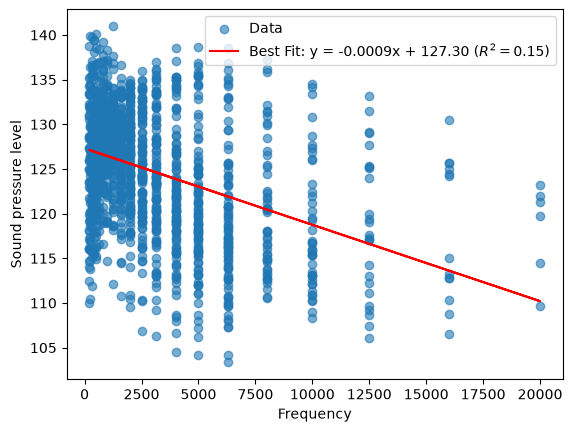

In [17]:
x = data["Frequency"]
y = data["Sound pressure level"]
fit = linregress(x, y)

plt.scatter(x, y, alpha=0.6, label="Data")
plt.plot(x, fit.intercept + fit.slope * x, color="red",
         label=f"Best Fit: y = {fit.slope:.4f}x + {fit.intercept:.2f} ($R^2={fit.rvalue**2:.2f}$)")
plt.xlabel("Frequency")
plt.ylabel("Sound pressure level")
plt.legend()
plt.show()

The plot shows that pressure generally decreases decreases as frequency increases, but there is a high rate of scatter, and the data does not fit the line well. Most data is clustered abround low frequencies, and only certain discrete frequency values contain data. The $R^2$ value of 0.153 shows that the line of best fit does not fit the data well.

## b) Univariate regressor

### Split data
- Source: [(https://www.geeksforgeeks.org/machine-learning/splitting-data-for-machine-learning-models/)]

`X` designates all of our independent variables (predictors), while y designates the single dependent variable (sound pressure level). Scikit-learn provides the `train_test_split()` function for creating random training and test split. `test_size=0.2` leaves 20% of the data for testing, allocating 80% for training. 

In [5]:
X = data.drop(columns="Sound pressure level")
y = data["Sound pressure level"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

### Fit linear regression with frequency as predictor

While part a) uses the entire dataset, part b) generates the line-of-best-fit using only the training data. 

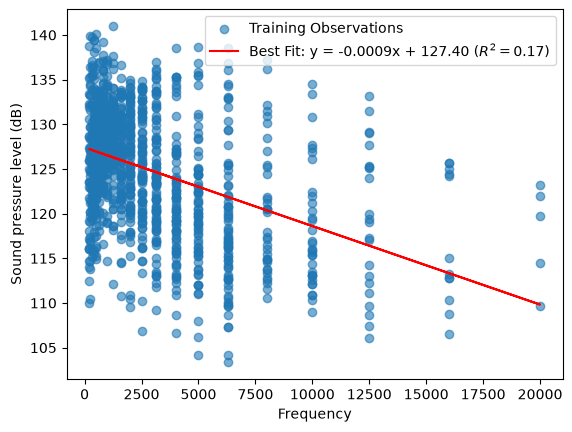

In [16]:
x = X_train["Frequency"]
fit = linregress(x, y_train)

plt.scatter(x, y_train, alpha=0.6, label="Training Observations")
plt.plot(x, fit.intercept + fit.slope * x, color="red",
         label=f"Best Fit: y = {fit.slope:.4f}x + {fit.intercept:.2f} ($R^2={fit.rvalue**2:.2f}$)")
plt.xlabel("Frequency")
plt.ylabel("Sound pressure level (dB)")
plt.legend()
plt.show()

The $R^2$ value is slightly higher than for part a), because now the line only has to fit the training data. The slope can be interpreted as: For each 1 Hz increase in frequency, the model predicts a -0.0009 dB change in sound pressure level.

## c) Multiple Linear Regression

SciPy Stats can be used for univariate regression, but for multivariate regression, we will need to use the Scikit-learn (`sklearn`) `LinearRegression` class. The line-of-best-fit is found by using the `.fit(x, y)` method. We use the `.predict(x)` method to predict the corresponding `y` using the line-of-best-fit. We then compute the error metrics between the predicted `y` and the true `y`.

We package the results into a dictionary, which we then turn into a pandas DataFrame. The `.T` operator transposes the DataFrame, swapping the rows and columns.

In [18]:
# Fit both models on the same training data
frequency_model = LinearRegression().fit(X_train[["Frequency"]], y_train)
multiple_model = LinearRegression().fit(X_train, y_train)

def metrics(model, X, y):
    predictions = model.predict(X)
    return {
        "RMSE": np.sqrt(mean_squared_error(y, predictions)),
        "R²": r2_score(y, predictions)}

results = pd.DataFrame({
    ("Training", "Frequency only"): metrics(frequency_model, X_train[["Frequency"]], y_train),
    ("Test", "Frequency only"): metrics(frequency_model, X_test[["Frequency"]], y_test),
    ("Training", "All predictors"): metrics(multiple_model, X_train, y_train),
    ("Test", "All predictors"): metrics(multiple_model, X_test, y_test),
}).T

display(results)

,,RMSE,R²
Training,Frequency only,6.248496,0.167789
Test,Frequency only,6.734021,0.094844
Training,All predictors,4.826601,0.503448
Test,All predictors,4.704109,0.558298


The model using all five predictors performs better on the testing data than the univariate model. RMSE drops from about 6.73 to 4.70, and $R^2$ rises from 0.095 to 0.558. This suggests additional predictors improve performance. For both models, training and testing performance appear similar, so there's no concern of overfitting.

## d) Plot multiple regression results

### Test residuals versus predicted values.

Plotting test residuals against predictions checks how well the model generalizes to unseen data. We should see a random spread around the zero axis. Patterns or changing spread indicate bias or non-linearity. 

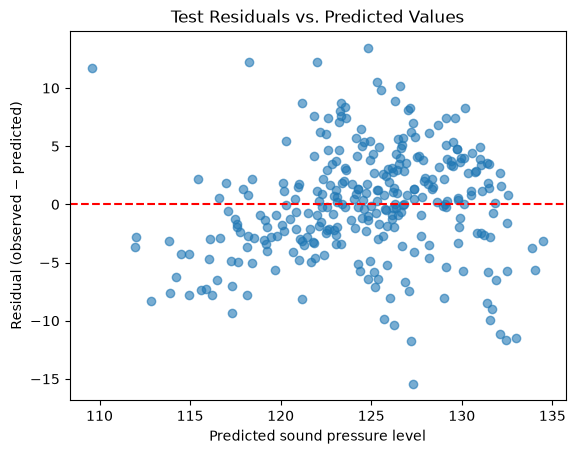

In [14]:
y_pred = multiple_model.predict(X_test)
residuals = y_test - y_pred

plt.scatter(y_pred, residuals, alpha=0.6)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted sound pressure level")
plt.ylabel("Residual (observed − predicted)")
plt.title("Test Residuals vs. Predicted Values")
plt.show()

The residuals are generally centered around zero, indicating that the model does not have a strong overall bias. The plot shows random scatter, with similar variance at dofferent sound pressure levels. There does seem to be slightly more spread underneath the zero line, suggesting the model may sometimes overpredict sound pressure levels, since negative residuals mean predicted values exceed observed values. However, this trend is subtle, and there is not enough evidence to conclude systematic bias.